# Laboratorium 4: Transformer jako model

W poprzednich laboratoriach pracowaliśmy z TF-IDF i gotowymi embeddingami. W tym laboratorium przechodzimy do modelu transformerowego używanego bezpośrednio jako klasyfikator.

Śledzimy cały przepływ:

`tekst → tokenizator → input_ids + attention_mask → enkoder → reprezentacja → głowa klasyfikacyjna → logity → predykcja`

Główne pytanie laboratorium brzmi:

**Co daje dostrajanie transformera i kiedy wzrost jakości uzasadnia dodatkowy koszt względem prostszego baseline'u?**

Porównamy:

- `TF-IDF + Linear SVM` z laboratorium 2;
- transformer z zamrożonym enkoderem;
- ten sam transformer po pełnym dostrojeniu.

Laboratorium obejmuje 10 zadań obowiązkowych i jedno opcjonalne.

## Po tych zajęciach student potrafi

- wyjaśnić różnicę między słowem, tokenem i subwordem;
- odczytać `input_ids` i `attention_mask`;
- wyjaśnić rolę paddingu i obcinania sekwencji;
- odczytać podstawowe informacje o architekturze modelu;
- wykonać przejście w przód bez użycia `pipeline()`;
- zinterpretować `last_hidden_state`, logity i wynik softmax;
- przygotować dane do klasyfikacji tekstu transformerem;
- porównać zamrożony enkoder z pełnym dostrajaniem;
- porównać transformera z klasycznym baseline'em;
- porównać model wielojęzyczny z polskim pod względem tokenizacji, jakości i kosztu (opcjonalnie);
- przeprowadzić analizę błędów i uzasadnić decyzję projektową.

## Dane i protokół

Pracujemy na tym samym zbiorze PolEmo 2.0 co w laboratoriach 1-3.

Obowiązuje ten sam protokół:

- `train` -- uczenie;
- `validation` -- porównywanie wariantów i wybór konfiguracji;
- `test` -- jedna końcowa ocena wybranego rozwiązania.

Wynik `TF-IDF + Linear SVM` z laboratorium 2 jest punktem odniesienia. Nie zmieniamy baseline'u po zobaczeniu wyników transformera.

Jeżeli ograniczenia sprzętowe wymagają zmniejszenia liczby przykładów treningowych, należy ustawić TRAIN_LIMIT (np. 2000, próbka stratyfikowana, ta sama we wszystkich eksperymentach transformerowych) i opisać to w karcie modelu.

## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow torch transformers datasets accelerate
```

Model używany w laboratorium:

```text
distilbert/distilbert-base-multilingual-cased
```

W Zadaniu 8 (opcjonalnie): `allegro/herbert-base-cased`, model wstępnie wytrenowany na korpusach polskich.


Kod startowy obejmuje importy, stałe i wczytanie danych. Implementacja właściwych eksperymentów należy do Państwa.

In [42]:
import math
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import re

from datasets import Dataset
from sklearn import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay, confusion_matrix,
)

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)

RANDOM_STATE = 42
set_seed(RANDOM_STATE)

ARTIFACTS = Path("../artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_NAME = "distilbert/distilbert-base-multilingual-cased"
MODEL_PL = "allegro/herbert-base-cased"   # zadanie 8 (opcjonalnie)
MAX_LENGTH = 128        # zadanie 2
TRAIN_LIMIT = None      # None = cały train; na CPU proponowane 2000

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if getattr(torch.backends, "mps", None)
    and torch.backends.mps.is_available()
    else "cpu"
)

print("Urządzenie:", DEVICE)

Urządzenie: mps


In [20]:
# helpery z labu 2 (bootstrap_ci, macro_f1) + nowe: paired_bootstrap_diff, token_stats

from sklearn.metrics import f1_score

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)
    
def paired_bootstrap_diff(y_true, pred_a, pred_b, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        diffs.append(metric(y_true[i], pred_b[i]) - metric(y_true[i], pred_a[i]))
    lo, hi = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, pred_b) - metric(y_true, pred_a)), float(lo), float(hi)

def token_stats(tokenizer, texts, max_length):
    texts = list(texts)
    ids = tokenizer(texts, add_special_tokens=True, truncation=False)["input_ids"]
    lens = np.array([len(x) for x in ids])
    n_words = np.array([len(re.findall(r"\w+", t)) for t in texts])
    return {
        "median": float(np.median(lens)),
        "p90": float(np.percentile(lens, 90)),
        "pct_truncated": float((lens > max_length).mean()),
        "tokens_per_word": float(lens.sum() / n_words.sum()),
    }

def inference_ms_per_doc(trainer):
    # mierzy predykcję na zbiorze ewaluacyjnym tego Trainera (stokenizowanym jego tokenizerem)
    dataset = trainer.eval_dataset
    t_s = time.perf_counter()
    trainer.predict(dataset)
    return (time.perf_counter() - t_s) / len(dataset) * 1000

In [21]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"].isin(["validation", "valid"])].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

if TRAIN_LIMIT is not None:
    train_df, _ = train_test_split(
        train_df, train_size=TRAIN_LIMIT, stratify=train_df["target"], random_state=RANDOM_STATE
    )
    train_df = train_df.reset_index(drop=True)

CLASSES = sorted(train_df["target"].unique())
print("train:", len(train_df), "validation:", len(val_df), "test:", len(test_df))

train: 5782 validation: 723 test: 722


# Zadanie 1: Audyt tokenizacji

Proszę wczytać tokenizator `MODEL_NAME` i przygotować co najmniej 8 polskich przykładów obejmujących wybrane zróżnicowane zjawiska z podanej poniżej listy:

- częste słowo;
- rzadkie słowo;
- nazwę własną;
- nazwisko;
- wyraz z polskimi znakami;
- ten sam wyraz bez polskich znaków;
- literówkę;
- neologizm;
- emoji;
- URL;
- liczbę;
- termin specjalistyczny.

Dla każdego przykładu proszę zapisać:

| tekst | liczba słów | liczba tokenów | tokeny | obserwacja |
|---|---:|---:|---|---|

Proszę krótko odpowiedzieć:

1. Czy token odpowiada słowu?
2. Jak tokenizator zachowuje się wobec nietypowych form?
3. Dlaczego tokenizacja może wpływać na późniejszy wynik modelu?

In [22]:
# Proszę wczytać tokenizator i przeprowadzić audyt tokenizacji.

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(type(bert_tokenizer))                          # np. <class '...TokenizerFast'>
print(bert_tokenizer.tokenize("Hotel był bardzo dobry."))
bert_tokenizer

<class 'transformers.models.bert.tokenization_bert.BertTokenizer'>
['Hotel', 'był', 'bardzo', 'dob', '##ry', '.']


BertTokenizer(name_or_path='distilbert/distilbert-base-multilingual-cased', vocab_size=119547, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

In [23]:
examples = [
    ("częste słowo", "To był bardzo dobry hotel."),
    ("rzadkie słowo", "Recepcjonista był wyjątkowo przeenergetyzowany."),
    ("nazwa własna", "Spędziliśmy weekend w Szczebrzeszynie."),
    ("nazwisko", "Polecam doktora Brzęczyszczykiewicza."),
    ("polskie znaki", "Na łóżku leżało źdźbło trawy."),
    ("bez polskich znaków", "Na lozku lezalo zdzblo trawy."),
    ("literówka", "Zdecydowanie rekomendujeę ten hotel."),
    ("neologizm", "Cały urlop to był plażing i smażing."),
    ("emoji", "Obsługa super 😍👍"),
    ("URL", "Zgadzam się z opinią: https://www.znanylekarz.pl/opinie"),
    ("liczba", "Za pobyt zapłaciłem 1234,50 zł."),
    ("termin specjalistyczny", "Lekarz zlecił elektroencefalografię."),
]

rows = []
for kind, text in examples:
    tokens = bert_tokenizer.tokenize(text)
    rows.append({
        "zjawisko": kind,
        "tekst": text,
        "liczba słów": len(text.split()),
        "liczba tokenów": len(tokens),
        "tokeny": " | ".join(tokens),
    })

audit_df = pd.DataFrame(rows)
audit_df["tokeny/słowo"] = (audit_df["liczba tokenów"] / audit_df["liczba słów"]).round(2)
audit_df

,zjawisko,tekst,liczba słów,liczba tokenów,tokeny,tokeny/słowo
0,częste słowo,To był bardzo dobry hotel.,5,7,To | był | bardzo | dob | ##ry | hotel | .,1.40
1,rzadkie słowo,Recepcjonista był wyjątkowo przeenergetyzowany.,4,18,Rec | ##ep | ##c | ##joni | ##sta | był | w | ...,4.50
2,nazwa własna,Spędziliśmy weekend w Szczebrzeszynie.,4,16,Sp | ##ę | ##dzi | ##li | ##ś | ##my | weekend...,4.00
3,nazwisko,Polecam doktora Brzęczyszczykiewicza.,3,11,Pole | ##cam | doktora | Br | ##zę | ##czy | #...,3.67
4,polskie znaki,Na łóżku leżało źdźbło trawy.,5,16,Na | ł | ##ó | ##ż | ##ku | le | ##żał | ##o |...,3.20
5,bez polskich znaków,Na lozku lezalo zdzblo trawy.,5,11,Na | lo | ##zku | lez | ##alo | z | ##dz | ##b...,2.20
6,literówka,Zdecydowanie rekomendujeę ten hotel.,4,11,Zde | ##cy | ##dowa | ##nie | re | ##komen | #...,2.75
7,neologizm,Cały urlop to był plażing i smażing.,7,15,Ca | ##ły | url | ##op | to | był | pla | ##ż ...,2.14
8,emoji,Obsługa super 😍👍,3,6,Ob | ##s | ##ług | ##a | super | [UNK],2.00
9,URL,Zgadzam się z opinią: https://www.znanylekarz....,5,23,Z | ##gad | ##zam | się | z | op | ##ini | ##ą...,4.60


**1. Czy token odpowiada słowu?**

Nie. We wszystkich przykładach liczba tokenów była większa niż liczba słów. Częste słowa mogą być pojedynczymi tokenami, ale rzadkie słowa, nazwiska, odmienione nazwy własne i terminy specjalistyczne są dzielone na kilka fragmentów (podsłów). Osobnymi tokenami są też znaki interpunkcyjne.

**2. Jak tokenizator zachowuje się wobec nietypowych form?**

Nietypowe formy są cięte na więcej i drobniejszych fragmentów. Zdanie z polskimi znakami dało o 5 tokenów więcej niż to samo zdanie bez nich, bo litery takie jak „ł”, „ó”, „ż” czy „ź” zostały wydzielone jako osobne tokeny. To samo słowo z polskimi znakami i bez nich jest więc dla modelu zupełnie inną sekwencją. Emoji tokenizator uznał za symbol nierozpoznany, czyli model nie dostaje o nim żadnej informacji.

**3. Dlaczego tokenizacja może wpływać na późniejszy wynik modelu?**

Model widzi wyłącznie tokeny, a nie słowa. Jeśli słowo zostanie pocięte na nietypowe fragmenty (literówka, brak polskich znaków), model dostaje inne tokeny niż te, których znaczenie poznał w treningu, i trudniej mu powiązać je z kontekstem. Gdy tokenizator zamienia coś na symbol nierozpoznany (emoji), informacja niesiona przez ten element ginie całkowicie. Dłuższe podziały zużywają też okno modelu, więc przy długich tekstach szybciej dochodzi do obcięcia końca tekstu.

# Zadanie 2: `input_ids`, `attention_mask`, padding i obcinanie

Proszę wybrać trzy teksty o różnej długości i przygotować je do wejścia modelu.

Dla każdego tekstu proszę wyświetlić:

- tokeny;
- `input_ids`;
- `attention_mask`;
- długość sekwencji.

Następnie proszę porównać `padding=True` oraz `padding="max_length", max_length=128` i policzyć, jaki procent pozycji w batchu stanowi padding.

Następnie proszę sprawdzić długości tokenowe wszystkich tekstów treningowych i podać:

- medianę;
- percentyl 90;
- percentyl 95;
- maksimum;
- procent tekstów obcinanych przy `MAX_LENGTH=128`.

Na tej podstawie proszę zdecydować, czy `128` jest rozsądną wartością dla dalszej części laboratorium (przy obcinaniu znika koniec tekstu, a w recenzjach często jest tam podsumowanie oceny). Decyzję i procent obciętych tekstów proszę zapisać w karcie modelu.

In [24]:
# Proszę zaimplementować analizę wejścia modelu i długości tokenowych.

short_text =  train_df[train_df["n_words"] < 15].head(1)["text"].iloc[0]
medium_mask = train_df["n_words"].between(101, 119)
medium_text = train_df[medium_mask]["text"].iloc[0]
long_text =  train_df[train_df["n_words"] > 200].head(1)["text"].iloc[0]

texts = [("short", short_text), ("medium" , medium_text), ("long", long_text)]
rows = []
for kind, text in texts:
    enc = bert_tokenizer(text)
    rows.append({
        "kind": kind,
        "n_words": len(text.split()),
        "seq_len": len(enc["input_ids"]),
        "tokens": bert_tokenizer.convert_ids_to_tokens(enc["input_ids"]),
        "input_ids": enc["input_ids"],
        "attention_mask": enc["attention_mask"],
    })

pd.DataFrame(rows)


,kind,n_words,seq_len,tokens,input_ids,attention_mask
0,short,15,24,"[[CLS], Just, ##yna, Ka, ##cz, ##oro, ##wska, ...","[101, 17116, 39017, 25444, 20868, 30700, 36580...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
1,medium,126,218,"[[CLS], Super, lekarz, i, cz, ##łowiek, przez,...","[101, 12786, 96015, 177, 53873, 98026, 11048, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
2,long,275,450,"[[CLS], Le, ##karz, ten, przyjął, m, ##nie, ni...","[101, 10281, 82497, 11769, 77460, 181, 11297, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."


In [25]:
batch_texts = [text for _, text in texts]

paddings = [
    ("padding=True", dict(padding=True)),
    ("padding='max_length', max_length=128", dict(padding="max_length", max_length=128)),
]

rows = []
for name, kwargs in paddings:
    batch =  bert_tokenizer(batch_texts, truncation=True, return_tensors="np", **kwargs)
    mask = batch["attention_mask"]

    rows.append({
        "wariant": name,
        "kształt batcha": mask.shape,
        "pozycje łacznie": mask.size,
        "padding": int((mask==0).sum()),
        "padding %": (mask ==0).mean() * 100
    })

padding_df = pd.DataFrame(rows)
padding_df

,wariant,kształt batcha,pozycje łacznie,padding,padding %
0,padding=True,"(3, 450)",1350,658,48.740741
1,"padding='max_length', max_length=128","(3, 128)",384,104,27.083333


In [26]:
train_texts = train_df["text"].tolist()

stats = token_stats(tokenizer=bert_tokenizer, texts=train_texts, max_length=MAX_LENGTH)

lens = np.array([len(x) for x in bert_tokenizer(train_texts, add_special_tokens=True, truncation=False)["input_ids"]])
stats["p95"] = float(np.percentile(lens, 95))
stats["max"] = int(lens.max())
stats["pct_truncated"] = stats["pct_truncated"] * 100

pd.Series(stats).round(2)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (539 > 512). Running this sequence through the model will result in indexing errors


median              222.50
p90                 415.90
pct_truncated        84.33
tokens_per_word       2.18
p95                 523.95
max                1807.00
dtype: float64

**Padding:** przy `padding=True` batch trzech tekstów ma kształt (3, 450), bo krótkie teksty są dopełniane do długości najdłuższego, więc padding stanowi 48.7% pozycji. Przy `padding="max_length", max_length=128` kształt jest stały (3, 128), a padding stanowi 27.1% pozycji, ale długi tekst traci ponad 2/3 tokenów. Dlatego w treningu używamy obcinania do `MAX_LENGTH` i dynamicznego paddingu w collatorze (do najdłuższego tekstu w batchu).

**Długości tokenowe (cały `train`, tokenizer DistilBERT-a):** mediana 222.5, p90 416, p95 524, maksimum 1807 tokenów. Przy `MAX_LENGTH=128` obcinanych jest **84.3%** tekstów, a ponad 5% przekracza nawet maksymalne okno modelu (512).

**Decyzja:** z punktu widzenia pokrycia tekstu 128 nie jest rozsądną wartością, bo model zwykle nie zobaczy końca recenzji, w którym często pada podsumowanie oceny. Zostawiamy jednak `MAX_LENGTH=128` jako kompromis kosztowy (czas treningu i pamięć na MPS), świadomie akceptując ten koszt jakościowy. Decyzja i procent obciętych tekstów są zapisane w karcie modelu.

# Zadanie 3: Co znajduje się w modelu?

Proszę wczytać bazowy enkoder przez `AutoModel` i odczytać z konfiguracji:

- rozmiar słownika;
- wymiar stanu ukrytego;
- liczbę warstw;
- liczbę głów uwagi;
- maksymalną długość sekwencji.

Następnie proszę samodzielnie policzyć:

- wszystkie parametry modelu;
- parametry trenowalne;
- przybliżony rozmiar samych wag w FP32 i FP16.

Proszę krótko wyjaśnić, dlaczego rzeczywiste zużycie pamięci podczas treningu jest większe niż rozmiar samych wag.


In [27]:
# Proszę wczytać AutoModel, odczytać konfigurację i policzyć parametry oraz przybliżony koszt pamięci wag.

baseline_encoder = AutoModel.from_pretrained(MODEL_NAME)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [28]:
baseline_cfg = baseline_encoder.config

config_info = {
    "rozmiar słownika": baseline_cfg.vocab_size,
    "wymiar stanu ukrytego": baseline_cfg.hidden_size,
    "liczbę warstw": baseline_cfg.num_hidden_layers,
    "liczbę głów uwagi": baseline_cfg.num_attention_heads,
    "maks. długość sekwencji (config)": baseline_cfg.max_position_embeddings,
    "maks. długość sekwencji (tokenizer)": bert_tokenizer.model_max_length,
}

n_params =  sum(p.numel() for p in baseline_encoder.parameters())
n_trainable = sum(p.numel() for p in baseline_encoder.parameters() if p.requires_grad)

memory_table = pd.DataFrame([
    ("wszystkie parametry", f"{n_params:,}".replace(",", " ")),
    ("parametry trenowalne", f"{n_trainable:,}".replace(",", " ")),
    ("wagi FP32 [MB]", f"{n_params * 4 / 1024**2:.1f}"),
    ("wagi FP16 [MB]", f"{n_params * 2 / 1024**2:.1f}"),
], columns=["parametr", "wartość"])


def as_table(d, value_name="wartość"):
    return pd.DataFrame(list(d.items()), columns=["parametr", value_name])

display(as_table(config_info))
display(memory_table)

,parametr,wartość
0,rozmiar słownika,119547
1,wymiar stanu ukrytego,768
2,liczbę warstw,6
3,liczbę głów uwagi,12
4,maks. długość sekwencji (config),512
5,maks. długość sekwencji (tokenizer),512


,parametr,wartość
0,wszystkie parametry,134 734 080
1,parametry trenowalne,134 734 080
2,wagi FP32 [MB],514.0
3,wagi FP16 [MB],257.0


Same wagi modelu w FP32 zajmują ok. 514 MB, ale podczas treningu w pamięci muszą się zmieścić jeszcze:

- **gradienty:** po jednym na każdą wagę, czyli kolejne ok. 514 MB;
- **stan optymalizatora:** AdamW przechowuje dla każdej wagi dwa dodatkowe bufory (średnią gradientów i średnią ich kwadratów), czyli ok. 2 × 514 ≈ 1028 MB;
- **aktywacje:** wyniki pośrednie każdej warstwy dla każdego przykładu w batchu, zapamiętywane do propagacji wstecznej. Ich rozmiar rośnie z rozmiarem batcha i długością sekwencji (a w mechanizmie uwagi kwadratowo z długością), więc przy `max_length=128` i większym batchu mogą zająć nawet więcej niż sam model;
- **narzut frameworka:** bufory tymczasowe, kopie przy mixed precision, fragmentacja pamięci GPU.

Same wagi, gradienty i stan AdamW to razem ok. 4 × 514 MB ≈ 2 GB, zanim w ogóle doliczymy aktywacje. Dlatego trening wymaga kilka razy więcej pamięci niż sama inferencja, w której potrzebne są tylko wagi i aktywacje bieżącego batcha (bez gradientów i bez stanu optymalizatora).

# Zadanie 4: Ręczne przejście w przód

Proszę wybrać jeden tekst i wykonać `tekst → tokenizator → tensory → AutoModel → last_hidden_state` bez użycia `pipeline()`.

Należy:

1. podać kształty tensorów wejściowych;
2. podać kształt `last_hidden_state`;
3. wyjaśnić znaczenie każdego wymiaru;
4. przypisać tokeny do odpowiadających im reprezentacji;
5. utworzyć jeden wektor dokumentu przez mean pooling z uwzględnieniem `attention_mask`.

Następnie proszę wczytać `AutoModelForSequenceClassification`, wykonać pojedynczą predykcję przed treningiem i:

- odczytać logity;
- zastosować softmax;
- sprawdzić, czy wartości po softmax sumują się do 1.

Proszę pamiętać, że wynik softmax nie jest automatycznie skalibrowaną miarą pewności modelu.

Na końcu proszę wyjaśnić, dlaczego predykcja z losowo zainicjalizowaną głową klasyfikacyjną nie ma jeszcze sensownej jakości.


In [29]:
# Proszę wykonać ręczne przejście w przód, mean pooling oraz analizę logitów i wyniku softmax.
mask =  train_df['n_words'].between(150, 200)
selected_text = train_df[mask].iloc[0]['text']
print(f"selected_text: --> {selected_text}")
print()

# 1–2. tekst -> tokenizator -> tensory
inputs =  bert_tokenizer(selected_text, return_tensors='pt', truncation=True, max_length=MAX_LENGTH)
print({k:tuple(v.shape) for k,v in inputs.items()})

# 3. tensory -> AutoModel -> last_hidden_state
baseline_encoder.eval()
with torch.no_grad():
    outputs =  baseline_encoder(**inputs)

hidden = outputs.last_hidden_state
print("last_hidden_state", tuple(hidden.shape))

# 4. przypisanie tokenów do reprezentacji
tokens =  bert_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

token_repr = pd.DataFrame({
    "pozycja": range(len(tokens)),
    "token": tokens,
    "pierwsze 3 wymiary wektora":[hidden[0, i, :3].numpy().round(3) for i in range(len(tokens))],
})
display(token_repr.head(10))

# 5. mean pooling z uwzględnieniem attention_mask
mask =  inputs["attention_mask"].unsqueeze(-1).float()
doc_vector = (hidden * mask).sum(dim=1) / mask.sum(dim=1)
print(f"wektor dokumentu:{tuple(doc_vector.shape)}")


selected_text: --> Krzysztof jest ZNAKOMITYM fizjoterapeutą ! Przyszła m do niego z wypadającym , krzywym kolanem , po operacji więzadła oraz z bolącą łękotką w drugim kolanie . Krzysztof po wywiadzie ogólnym oraz badaniu stwierdził szybko co może na to pomóc i jak temu przeciwdziałać . Jego wiedza + intensywne zestawy ćwiczeń , zaangażowanie i chęci robią " cuda " ! Otworzył mi oczy , że to , to i to nie działa i nie funkcjonuje normalnie dlatego tak i tak się dzieje . Teraz moja praca oraz treningi stały się w końcu czystą przyjemnością a nie walką z samą sobą ! : ) POLECAM ! Na zakończenie dodam , że po kilku wizytach przyprowadziła m swoją mamą , która przez 9mc borykała się ostrym bólem barków , odwiedzając przez ten okres przeróżnych specjalistów , doktorów płacąc przy tym majątek . W dodatku nikt przez ten czas nie pomógł jej ani trochę i codziennie z bólu łykała po 2 - 3 tabletki przeciw bólowe . Po wizycie u Krzyśka okazało się , że ma zerwane ścięgna . A po jego pierwszej , 3

,pozycja,token,pierwsze 3 wymiary wektora
0,0,[CLS],"[0.134, 0.049, 0.094]"
1,1,Krzysztof,"[-0.192, 0.067, 0.4]"
2,2,jest,"[0.3, 0.079, 0.281]"
3,3,Z,"[0.491, -0.333, 0.216]"
4,4,##NA,"[0.431, 0.105, 0.378]"
5,5,##KO,"[0.313, -0.032, -0.125]"
6,6,##MI,"[0.642, 0.112, 0.313]"
7,7,##T,"[0.705, -0.034, -0.219]"
8,8,##Y,"[0.245, -0.499, -0.041]"
9,9,##M,"[0.798, -0.221, 0.348]"


wektor dokumentu:(1, 768)


In [30]:
clf_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)

clf_model.eval()
with torch.no_grad():
    logits =  clf_model(**inputs).logits

probs =  torch.softmax(logits, dim=1)
print("logity:", logits.numpy().round(4))
print("softmax:", probs.numpy().round(4))
print("suma po softmax:", probs.sum().item())

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


logity: [[-0.0078 -0.0488 -0.0031  0.0968]]
softmax: [[0.2454 0.2356 0.2466 0.2725]]
suma po softmax: 1.0


Uwaga do zadań 3-4: Nazwy pól w konfiguracji DistilBERT różnią się od BERT-a (`dim`, `n_layers`, `n_heads`), ale działają też aliasy (`hidden_size`, `num_hidden_layers`, `num_attention_heads`).

Przy ładowaniu `AutoModelForSequenceClassification` pojawi się ostrzeżenie o nowo zainicjalizowanych wagach. Proszę wyjaśnić, które to wagi i dlaczego jest to oczekiwane.

Którą pozycję z `last_hidden_state` wykorzystuje głowa klasyfikacyjna tego modelu i czym różni się to od mean poolingu?

**1–3. Kształty tensorów i znaczenie wymiarów**

- `input_ids`, `attention_mask` (i `token_type_ids`): **(1, 128)**. 1 to rozmiar batcha (jeden tekst), 128 to liczba tokenów. Tekst był dłuższy niż `MAX_LENGTH`, więc został obcięty do 128 tokenów: końcowe zdania recenzji („Krzysiek jest naprawdę GODNYM POLECENIA SPECJALISTĄ…”) nie trafiły do modelu.
- `last_hidden_state`: **(1, 128, 768)**. Kolejne wymiary to batch, pozycja tokenu w sekwencji i wymiar stanu ukrytego (`hidden_size` = 768). Każdy token dostaje własny wektor 768 liczb, zależny od kontekstu całego zdania.

**4. Tokeny a reprezentacje**

Wiersz `i` w `last_hidden_state[0]` odpowiada tokenowi `tokens[i]`: pozycja 0 to `[CLS]`, potem „Krzysztof”, „jest” itd. Słowo pisane wielkimi literami „ZNAKOMITYM” zostało rozbite na 7 tokenów (`Z`, `##NA`, `##KO`, `##MI`, `##T`, `##Y`, `##M`), więc ma 7 osobnych wektorów, a nie jeden.

**5. Mean pooling**

Wektory tokenów mnożymy przez `attention_mask` i uśredniamy po pozycjach, dzięki czemu tokeny paddingu nie wpływają na wynik. Otrzymujemy jeden wektor dokumentu o kształcie **(1, 768)**. W tym przykładzie maska ma same jedynki (pojedynczy, obcięty tekst bez paddingu), więc wynik jest równy zwykłej średniej. Maska ma znaczenie dopiero w batchu z paddingiem.

**Predykcja przed treningiem**

Logity: [-0.008, -0.049, -0.003, 0.097]. Po softmax: [0.245, 0.236, 0.247, 0.273], suma = 1.0. Rozkład jest prawie równomierny (ok. 0.25 na każdą z 4 klas), a różnice wynikają tylko z losowych wag. Softmax zawsze sumuje się do 1, więc nawet taki przypadkowy wynik wygląda jak „prawdopodobieństwa”, choć nie jest skalibrowaną miarą pewności.

**Dlaczego predykcja z losową głową nie ma sensu?**

Enkoder jest wytrenowany i daje sensowne reprezentacje tekstu, ale głowa klasyfikacyjna ma losowe wagi. Nie wie, który kierunek w 768-wymiarowej przestrzeni odpowiada której klasie (`plus`, `minus`, `zero`, `amb`), więc jej wynik jest przypadkowy. Sensowne predykcje pojawią się dopiero po fine-tuningu na danych z etykietami.

**Które wagi są nowo zainicjalizowane i dlaczego to oczekiwane?**

Raport pokazuje jako `MISSING` wagi `pre_classifier` (warstwa 768 → 768) i `classifier` (768 → 4 klasy). Checkpoint `distilbert-base-multilingual-cased` był pretrenowany tylko do przewidywania zamaskowanych słów, więc nie zawiera głowy do klasyfikacji sentymentu i biblioteka tworzy ją z losowymi wagami. Jako `UNEXPECTED` pomijana jest z kolei głowa MLM (`vocab_transform`, `vocab_layer_norm`, `vocab_projector`), niepotrzebna do klasyfikacji. Oba ostrzeżenia są oczekiwane przy przenoszeniu modelu na nowe zadanie.

**Którą pozycję wykorzystuje głowa klasyfikacyjna i czym różni się to od mean poolingu?**

`DistilBertForSequenceClassification` bierze tylko wektor z **pozycji 0, czyli tokenu `[CLS]`** (`last_hidden_state[:, 0]`), i przepuszcza go przez `pre_classifier` i `classifier`. Mean pooling uśrednia wektory **wszystkich** prawdziwych tokenów. Wektor `[CLS]` musi dopiero nauczyć się w trakcie fine-tuningu zbierać informację o całym tekście; DistilBERT nie był pretrenowany z zadaniem, które by go do tego przygotowało. Mean pooling daje sensowny wektor dokumentu bez dodatkowego treningu, ale traktuje wszystkie tokeny jednakowo.

# Zadanie 5: Przygotowanie klasyfikatora

Proszę przygotować pełny pipeline treningowy dla klasyfikacji PolEmo 2.0.

Należy samodzielnie:

1. przygotować mapowania `label2id` i `id2label`;
2. utworzyć obiekty `Dataset` dla `train` i `validation`;
3. napisać funkcję tokenizującą batch;
4. użyć dynamicznego `DataCollatorWithPadding`;
5. zaimplementować `compute_metrics`;
6. przygotować `TrainingArguments`;
7. utworzyć `Trainer`.

Główną metryką jest `macro-F1`.

Konfiguracja domyślna (zmiana tylko z uzasadnieniem): 3 epoki, batch size 16, `weight_decay=0.01`, `warmup_ratio=0.1`, `MAX_LENGTH` z Zadania 2.

Proszę ustawić `report_to="none"` i `save_strategy="no"` (domyślnie `Trainer` zapisuje checkpointy po ok. 0,5 GB). Nazwy argumentów `TrainingArguments` i `Trainer` zmieniały się między wersjami `transformers` (m.in. `evaluation_strategy` → `eval_strategy`, `tokenizer` → `processing_class`), więc proszę zapisać `import transformers`.

Proszę zapisać użyte `MAX_LENGTH`, batch size, learning rate, liczbę epok, seed i urządzenie.

In [31]:
# Proszę przygotować dane i pipeline treningowy.

BATCH_SIZE = 16
LEARNING_RATE = 5e-5
NUM_EPOCHS = 3

steps_per_epoch = math.ceil(len(train_df) / BATCH_SIZE)
WARMUP_STEPS = int(0.1 * steps_per_epoch * NUM_EPOCHS)

label2id = {label: i for i, label in enumerate(CLASSES)}
id2label = {i: label for label, i in label2id.items()}


def make_dataset(df, tok):
    ds = Dataset.from_dict({
        "text": df["text"].tolist(),
        "labels": df["target"].map(label2id).tolist(),
    })

    def tokenize_batch(batch):
        return tok(batch["text"], truncation=True, max_length=MAX_LENGTH)

    return ds.map(tokenize_batch, batched=True, remove_columns=["text"])


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)
    return {
        "macro_f1": macro_f1(labels, predictions),
        "accuracy": accuracy_score(labels, predictions),
    }


def make_model(model_name):
    return AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(CLASSES), id2label=id2label, label2id=label2id, attn_implementation="eager"
    )


def make_trainer(model, learning_rate, train_ds, eval_ds, tok, eval_each_epoch=True, warmup_steps=None):
    args = TrainingArguments(
        output_dir="trainer_output",
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=learning_rate,
        weight_decay=0.01,
        warmup_steps=WARMUP_STEPS if warmup_steps is None else warmup_steps,
        eval_strategy="epoch" if eval_each_epoch else "no",
        save_strategy="no",
        report_to="none",
        seed=RANDOM_STATE,
        logging_steps=50,
        dataloader_pin_memory=False,
    )
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tok,
        data_collator=DataCollatorWithPadding(tokenizer=tok),
        compute_metrics=compute_metrics,
    )


train_dataset = make_dataset(train_df, bert_tokenizer)
validation_dataset = make_dataset(val_df, bert_tokenizer)

trainer = make_trainer(make_model(MODEL_NAME), LEARNING_RATE, train_dataset, validation_dataset, bert_tokenizer)

print(f"MAX_LENGTH={MAX_LENGTH}, batch={BATCH_SIZE}, lr={LEARNING_RATE},epochs={NUM_EPOCHS}, seed={RANDOM_STATE}, device={trainer.args.device}")

Map:   0%|          | 0/5782 [00:00<?, ? examples/s]

Map:   0%|          | 0/723 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


MAX_LENGTH=128, batch=16, lr=5e-05,epochs=3, seed=42, device=mps


# Zadanie 6: Zamrożony enkoder

Proszę załadować model klasyfikacyjny i zamrozić cały enkoder (`model.base_model`). Trenowana ma być wyłącznie głowa klasyfikacyjna (w DistilBERT: `pre_classifier` i `classifier`).

Learning rate dla tego wariantu proszę dobrać osobno (typowo ok. `1e-3`; wartość rzędu `2e-5` prawie nie uczy samej głowy w trzech epokach). Liczba epok i pozostałe warunki są takie same jak w zadaniu 5.

Proszę:

1. policzyć liczbę wszystkich parametrów;
2. policzyć liczbę parametrów trenowalnych;
3. podać procent parametrów trenowalnych;
4. wytrenować model;
5. zmierzyć czas treningu;
6. obliczyć accuracy i macro-F1 na zbiorze walidacyjnym.

Przed treningiem proszę zapisać hipotezę dotyczącą oczekiwanej jakości tego wariantu.

**Hipoteza:** wariant z zamrożonym enkoderem będzie wyraźnie słabszy od pełnego dostrajania i prawdopodobnie od baseline'u TF-IDF + LogReg z Lab 2 (macro-F1 0.80), bo trenujemy tylko głowę klasyfikacyjną (ok. 0.44% parametrów), a reprezentacje enkodera nie są dopasowane do sentymentu.

In [32]:
# Proszę zaimplementować wariant z zamrożonym enkoderem.

frozen_model = make_model(MODEL_NAME)

for p in frozen_model.base_model.parameters():
    p.requires_grad = False

FROZEN_LR = 1e-3
frozen_trainer = make_trainer(frozen_model, FROZEN_LR, train_dataset, validation_dataset, bert_tokenizer)

frozen_n_params = sum(p.numel() for p in frozen_model.parameters())
frozen_n_trainable = sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)

frozen_params_table = pd.DataFrame([
    ("wszystkie parametry", f"{frozen_n_params:,}".replace(",", " ")),
    ("parametry trenowalne", f"{frozen_n_trainable:,}".replace(",", " ")),
    ("procent parametrów trenowalnych", f"{frozen_n_trainable / frozen_n_params:.2%}"),
], columns=["parametr", "wartość"])
display(frozen_params_table)


t_s = time.perf_counter()
frozen_trainer.train()
t_e = time.perf_counter()
frozen_train_s = t_e - t_s

frozen_out = frozen_trainer.predict(validation_dataset)
frozen_val_pred = frozen_out.predictions.argmax(axis=1)
frozen_ms_doc = inference_ms_per_doc(frozen_trainer)


print(f"Train time: {frozen_train_s:.1f} s")
print(f"accuracy: {frozen_out.metrics['test_accuracy']:.3f}")
print(f"macro-F1: {frozen_out.metrics['test_macro_f1']:.3f}")
print(f"ms/doc: {frozen_ms_doc:.1f}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,parametr,wartość
0,wszystkie parametry,135 327 748
1,parametry trenowalne,593 668
2,procent parametrów trenowalnych,0.44%


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.040091,1.068597,0.445801,0.437068
2,0.892363,0.853896,0.555877,0.645920
3,0.869818,0.810213,0.580958,0.677732


Train time: 31.1 s
accuracy: 0.678
macro-F1: 0.581
ms/doc: 1.5


**Weryfikacja hipotezy:** hipoteza się potwierdziła. Wariant z zamrożonym enkoderem osiągnął macro-F1 0.581 (accuracy 0.678), czyli wyraźnie więcej niż losowe 0.25, ale znacznie mniej niż baseline TF-IDF + Linear SVM (0.788) i pełne dostrajanie (0.768, Zadanie 7). Trening trwał tylko ok. 31 s, bo gradienty liczone są wyłącznie dla głowy (593 668 parametrów, 0.44%).

# Zadanie 7: Pełne dostrajanie i porównanie na walidacji

Proszę załadować świeżą kopię tego samego checkpointu i przeprowadzić pełne dostrajanie modelu.

Warunki: ten sam podział danych, to samo `MAX_LENGTH`, ten sam sposób ewaluacji i ta sama liczba epok co w Zadaniu 5. Learning rate dobieramy osobno do wariantu (pełne dostrajanie: typowo `2e-5`–`5e-5`).

Dla wariantu dostrojonego proszę zmierzyć: liczbę parametrów trenowalnych, czas treningu, accuracy, macro-F1 i średni czas inferencji na dokument (ta sama maszyna, podany batch size).

| model | trainable params | train_s | ms/doc | accuracy | macro-F1 | macro-F1 CI95 |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF + Linear SVM | -- | | | | | |
| frozen transformer | | | | | | |
| fine-tuned transformer | | | | | | |

Przedział ufności liczymy funkcją `bootstrap_ci` z Lab 2. Predykcje walidacyjne obu transformerów proszę zapisać (będą potrzebne w Zadaniach 8 i 10).

Opcjonalnie: proszę powtórzyć dostrajanie dla drugiego seeda. Dostrajanie ma wyraźną wariancję między seedami, więc różnic rzędu kilku dziesiątych punktu macro-F1 nie należy traktować jako przewagi.

In [33]:
# Proszę przeprowadzić pełne dostrajanie, zapisać predykcje walidacyjne i uzupełnić tabelę.

ft_model = make_model(MODEL_NAME)
ft_trainer = make_trainer(ft_model, LEARNING_RATE, train_dataset, validation_dataset, bert_tokenizer)

ft_n_params = sum(p.numel() for p in ft_model.parameters())
ft_n_trainable = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)

ft_params_table = pd.DataFrame([
    ("wszystkie parametry", f"{ft_n_params:,}".replace(",", " ")),
    ("parametry trenowalne", f"{ft_n_trainable:,}".replace(",", " ")),
    ("procent parametrów trenowalnych", f"{ft_n_trainable / ft_n_params:.2%}"),
], columns=["parametr", "wartość"])
display(ft_params_table)


t_s = time.perf_counter()
ft_trainer.train()
t_e = time.perf_counter()
ft_train_s = t_e - t_s

ft_out = ft_trainer.predict(validation_dataset)
ft_val_pred = ft_out.predictions.argmax(axis=1)
val_true = ft_out.label_ids

_, ft_lo, ft_hi = bootstrap_ci(y_true=val_true, y_pred=ft_val_pred, metric=macro_f1)

ft_ms_doc = inference_ms_per_doc(ft_trainer)

print(f"Train time: {ft_train_s:.1f} s")
print(f"accuracy: {ft_out.metrics['test_accuracy']:.3f}")
print(f"macro-F1: {ft_out.metrics['test_macro_f1']:.3f} (95% CI: {ft_lo:.3f}–{ft_hi:.3f})")
print(f"ms/doc: {ft_ms_doc:.1f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,parametr,wartość
0,wszystkie parametry,135 327 748
1,parametry trenowalne,135 327 748
2,procent parametrów trenowalnych,100.00%


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.694160,0.635009,0.727828,0.726141
2,0.494179,0.553707,0.763658,0.793914
3,0.275611,0.614555,0.767780,0.785615


Train time: 302.6 s
accuracy: 0.786
macro-F1: 0.768 (95% CI: 0.738–0.797)
ms/doc: 1.4


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# --- baseline: TF-IDF + Linear SVM (konfiguracja z Lab 2), te same dane co transformery ---
svm_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True)),
    ("clf", LinearSVC(random_state=RANDOM_STATE)),
])
y_train_ids = train_df["target"].map(label2id).to_numpy()

t_s = time.perf_counter()
svm_pipe.fit(train_df["text"], y_train_ids)
svm_train_s = time.perf_counter() - t_s

t_s = time.perf_counter()
svm_val_preds = svm_pipe.predict(val_df["text"])
svm_ms_doc = (time.perf_counter() - t_s) / len(val_df) * 1000


def row(name, trainable, train_s, ms_doc, preds):
    f1, lo, hi = bootstrap_ci(val_true, preds, metric=macro_f1)
    return {
        "model": name,
        "trainable params": trainable,
        "train_s": round(train_s, 1),
        "ms/doc": round(ms_doc, 3),
        "accuracy": round(accuracy_score(val_true, preds), 3),
        "macro-F1": round(f1, 3),
        "macro-F1 CI95": f"{lo:.3f}–{hi:.3f}",
    }

comparison_df = pd.DataFrame([
    row("TF-IDF + Linear SVM", "--", svm_train_s, svm_ms_doc, svm_val_preds),
    row("frozen transformer", f"{frozen_n_trainable:,}".replace(",", " "), frozen_train_s, frozen_ms_doc, frozen_val_pred),
    row("fine-tuned transformer", f"{ft_n_trainable:,}".replace(",", " "), ft_train_s, ft_ms_doc, ft_val_pred),
])
comparison_df

,model,trainable params,train_s,ms/doc,accuracy,macro-F1,macro-F1 CI95
0,TF-IDF + Linear SVM,--,0.9,0.058,0.822,0.788,0.758–0.817
1,frozen transformer,593 668,31.1,1.469,0.678,0.581,0.557–0.606
2,fine-tuned transformer,135 327 748,302.6,1.377,0.786,0.768,0.738–0.797


- **Pełne dostrajanie vs zamrożony enkoder:** macro-F1 rośnie z 0.581 do 0.768 przy ok. 10× dłuższym treningu (303 s vs 31 s). Czas inferencji jest praktycznie taki sam (ok. 1.4 ms/dok.), bo architektura się nie zmienia.
- **Transformer vs TF-IDF + Linear SVM:** dostrojony DistilBERT (0.768, CI 0.738–0.797) nie jest lepszy od baseline'u (0.788, CI 0.758–0.817). Sparowana różnica wynosi −0.020 (95% CI −0.056 do +0.013), więc modele są statystycznie nieodróżnialne. Transformer trenuje się przy tym ok. 300× dłużej i jest ok. 24× wolniejszy w inferencji.
- **Wyniki wariantów TF-IDF są zgodne z Lab 2** (macro-F1 0.788 na tej samej walidacji), co potwierdza poprawność porównania.

# (opcjonalnie) Zadanie 8: Model polski czy wielojęzyczny?

Dotychczas używaliśmy `distilbert-base-multilingual-cased` (6 warstw, słownik wielojęzyczny). Sprawdzimy, czy model wstępnie wytrenowany na polskich korpusach, `allegro/herbert-base-cased` (BERT, 12 warstw, słownik 50 tys. tokenów), daje przewagę i za jaką cenę.

## Część A: tokenizacja (bez treningu)

Proszę wczytać oba tokenizatory (HerBERT: `AutoTokenizer.from_pretrained(MODEL_PL)`) i dla 500 losowych dokumentów z `train_df` policzyć funkcją `token_stats`: medianę i p90 liczby tokenów, procent tekstów obciętych przy `MAX_LENGTH` oraz liczbę tokenów na słowo.

Następnie proszę porównać podział przykładów z Zadania 1 (także form z odciętą końcówką osobową, np. `Był em`, `miała m`) i zapisać, które słowa dzielą się inaczej.

## Część B: dostrajanie

Proszę dostroić HerBERT-a w tych samych warunkach co dostrojony DistilBERT z Zadania 7: te same `MAX_LENGTH`, liczba epok, batch size, seed i próbka danych, learning rate z tego samego przedziału. Przy ładowaniu `AutoModelForSequenceClassification` pojawi się ostrzeżenie o nowo zainicjalizowanych wagach. Proszę zapisać, które warstwy są nowe.

## Część C: porównanie

Proszę rozszerzyć tabelę z Zadania 7 o wiersz `fine-tuned HerBERT` (trainable params, train_s, ms/doc, accuracy, macro-F1, CI95) oraz policzyć różnicę macro-F1 (HerBERT − DistilBERT) z przedziałem ufności funkcją `paired_bootstrap_diff` na tych samych przykładach walidacyjnych.

Pytania:

1. Który model ma więcej parametrów, a który jest wolniejszy? Dlaczego liczba parametrów nie wystarcza do oszacowania kosztu obliczeń?
2. Czy różnica jakości jest istotna w świetle przedziału ufności?
3. Czy tokenizatory inaczej dzielą polskie formy (Część A)? Czy na podstawie tego eksperymentu można stwierdzić, że to wyjaśnia różnicę jakości?

In [36]:
herbert_tokenizer = AutoTokenizer.from_pretrained(MODEL_PL)

train_texts_sample = train_df["text"].sample(n=500, random_state=RANDOM_STATE).tolist()

herbert_stats = token_stats(tokenizer=herbert_tokenizer, texts=train_texts_sample, max_length=MAX_LENGTH)
distilbert_stats = token_stats(tokenizer=bert_tokenizer, texts=train_texts_sample, max_length=MAX_LENGTH)

tokenizer_cmp_df = pd.DataFrame(
    [distilbert_stats, herbert_stats],
    index=["DistilBERT multilingual", "HerBERT"],
)
tokenizer_cmp_df["pct_truncated"] = tokenizer_cmp_df["pct_truncated"] * 100
tokenizer_cmp_df.round(2)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (530 > 512). Running this sequence through the model will result in indexing errors


,median,p90,pct_truncated,tokens_per_word
DistilBERT multilingual,215.0,397.5,83.6,2.17
HerBERT,145.0,272.1,59.2,1.46


In [37]:
extra_examples = [
    ("odcięta końcówka osobowa", "Był em tam wczoraj ."),
    ("odcięta końcówka osobowa", "Pani doktor była miła , ale miała m wątpliwości ."),
]

tokenizers = [("DistilBERT", bert_tokenizer), ("HerBERT", herbert_tokenizer)]

rows = []
for kind, text in examples + extra_examples:
    record = {"zjawisko": kind, "tekst": text, "liczba słów": len(text.split())}
    for name, tok in tokenizers:
        tokens = tok.tokenize(text)
        record[f"{name}: liczba tokenów"] = len(tokens)
        record[f"{name}: tokeny"] = " | ".join(tokens)
    record["różnica tokenów (DistilBERT − HerBERT)"] = record["DistilBERT: liczba tokenów"] - record["HerBERT: liczba tokenów"]
    rows.append(record)

tokenizer_comparison_df = pd.DataFrame(rows)
tokenizer_comparison_df

,zjawisko,tekst,liczba słów,DistilBERT: liczba tokenów,DistilBERT: tokeny,HerBERT: liczba tokenów,HerBERT: tokeny,różnica tokenów (DistilBERT − HerBERT)
0,częste słowo,To był bardzo dobry hotel.,5,7,To | był | bardzo | dob | ##ry | hotel | .,6,To</w> | był</w> | bardzo</w> | dobry</w> | ho...,1
1,rzadkie słowo,Recepcjonista był wyjątkowo przeenergetyzowany.,4,18,Rec | ##ep | ##c | ##joni | ##sta | był | w | ...,11,Re | cep | cjoni | sta</w> | był</w> | wyjątko...,7
2,nazwa własna,Spędziliśmy weekend w Szczebrzeszynie.,4,16,Sp | ##ę | ##dzi | ##li | ##ś | ##my | weekend...,9,Sp | ędzi | liśmy</w> | weekend</w> | w</w> | ...,7
3,nazwisko,Polecam doktora Brzęczyszczykiewicza.,3,11,Pole | ##cam | doktora | Br | ##zę | ##czy | #...,8,Polecam</w> | doktora</w> | B | rzę | czy | sz...,3
4,polskie znaki,Na łóżku leżało źdźbło trawy.,5,16,Na | ł | ##ó | ##ż | ##ku | le | ##żał | ##o |...,9,Na</w> | łóżku</w> | leżało</w> | ź | dź | b |...,7
5,bez polskich znaków,Na lozku lezalo zdzblo trawy.,5,11,Na | lo | ##zku | lez | ##alo | z | ##dz | ##b...,12,Na</w> | lo | z | ku</w> | le | za | lo</w> | ...,-1
6,literówka,Zdecydowanie rekomendujeę ten hotel.,4,11,Zde | ##cy | ##dowa | ##nie | re | ##komen | #...,8,Zdecydowanie</w> | rekomen | du | je | ę</w> |...,3
7,neologizm,Cały urlop to był plażing i smażing.,7,15,Ca | ##ły | url | ##op | to | był | pla | ##ż ...,12,Cały</w> | urlop</w> | to</w> | był</w> | pla ...,3
8,emoji,Obsługa super 😍👍,3,6,Ob | ##s | ##ług | ##a | super | [UNK],5,Obsłu | ga</w> | super</w> | <unk> | <unk>,1
9,URL,Zgadzam się z opinią: https://www.znanylekarz....,5,23,Z | ##gad | ##zam | się | z | op | ##ini | ##ą...,19,Zgadzam</w> | się</w> | z</w> | opinią</w> | :...,4


**Które słowa dzielą się inaczej?**

- **Oba tokenizery inaczej oznaczają granice słów.** DistilBERT (WordPiece) oznacza kontynuację słowa prefiksem `##`, a HerBERT (BPE) oznacza koniec słowa sufiksem `</w>`.
- **HerBERT zostawia całe częste polskie słowa, które DistilBERT dzieli:** „dobry” (`dob | ##ry`), „Polecam” (`Pole | ##cam`), „Lekarz” (`Le | ##karz`), „miła” (`mi | ##ła`), „wczoraj” (`w | ##cz | ##ora | ##j`), „łóżku”, „leżało”, „wyjątkowo”, „Zdecydowanie”, „wątpliwości”. Łącznie na 14 przykładach DistilBERT potrzebuje 185 tokenów, a HerBERT 132, czyli ok. 30% mniej.
- **Polskie znaki:** DistilBERT tnie słowa z diakrytykami prawie na pojedyncze litery („łóżku” → `ł | ##ó | ##ż | ##ku`), więc to zdanie ma u niego 16 tokenów, a u HerBERT-a 9.
- **Tekst bez polskich znaków to jedyny przypadek, w którym HerBERT wypada gorzej** (12 vs 11 tokenów). „lozku” i „lezalo” nie występują w polskim słowniku, więc rozpadają się na drobne fragmenty.
- **Nazwy własne i terminy dzielą oba tokenizery, ale HerBERT na mniej części:** „Brzęczyszczykiewicza” (7 vs 5 fragmentów), „elektroencefalografię” (7 vs 5), „Szczebrzeszynie” (8 vs 3).
- **Liczba:** tu lepszy jest DistilBERT, bo „1234” to u niego jeden token, a HerBERT dzieli ją na `12 | 34`.
- **Odcięte końcówki osobowe** („Był em”, „miała m”) oba tokenizery traktują jako osobne tokeny (`em`, `m`), więc model nie widzi formy „byłem” jako jednego słowa.
- **Emoji** oba zamieniają na token nieznany: DistilBERT robi jeden `[UNK]` z dwóch emoji, a HerBERT dwa `<unk>`. W obu przypadkach informacja ginie.

**Wniosek:** słownik HerBERT-a jest lepiej dopasowany do polszczyzny. Krótsze sekwencje oznaczają, że przy `MAX_LENGTH=128` model zobaczy większą część recenzji, a pojedyncze tokeny dla całych słów niosą więcej znaczenia niż fragmenty liter. Przewaga znika jednak przy tekstach bez polskich znaków.

In [38]:
herbert_train_dataset = make_dataset(train_df, herbert_tokenizer)
herbert_validation_dataset = make_dataset(val_df, herbert_tokenizer)

herbert_ft_model = make_model(MODEL_PL)
herbert_ft_trainer = make_trainer(herbert_ft_model, LEARNING_RATE, herbert_train_dataset, herbert_validation_dataset, herbert_tokenizer)

herbert_ft_n_params = sum(p.numel() for p in herbert_ft_model.parameters())
herbert_ft_n_trainable = sum(p.numel() for p in herbert_ft_model.parameters() if p.requires_grad)

herbert_ft_params_table = pd.DataFrame([
    ("wszystkie parametry", f"{herbert_ft_n_params:,}".replace(",", " ")),
    ("parametry trenowalne", f"{herbert_ft_n_trainable:,}".replace(",", " ")),
    ("procent parametrów trenowalnych", f"{herbert_ft_n_trainable / herbert_ft_n_params:.2%}"),
], columns=["parametr", "wartość"])
display(herbert_ft_params_table)


t_s = time.perf_counter()
herbert_ft_trainer.train()
t_e = time.perf_counter()
herbert_ft_train_s = t_e - t_s

herbert_ft_out = herbert_ft_trainer.predict(herbert_validation_dataset)
herbert_ft_val_pred = herbert_ft_out.predictions.argmax(axis=1)

_, herbert_ft_lo, herbert_ft_hi = bootstrap_ci(y_true=val_true, y_pred=herbert_ft_val_pred, metric=macro_f1)

herbert_ft_ms_doc = inference_ms_per_doc(herbert_ft_trainer)

print(f"Train time: {herbert_ft_train_s:.1f} s")
print(f"accuracy: {herbert_ft_out.metrics['test_accuracy']:.3f}")
print(f"macro-F1: {herbert_ft_out.metrics['test_macro_f1']:.3f} (95% CI: {herbert_ft_lo:.3f}–{herbert_ft_hi:.3f})")
print(f"ms/doc: {herbert_ft_ms_doc:.1f}")

Map:   0%|          | 0/5782 [00:00<?, ? examples/s]

Map:   0%|          | 0/723 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allegro/herbert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.sso.sso_relationship.weight            | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.sso.sso_relationship.bias              | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

,parametr,wartość
0,wszystkie parametry,124 445 956
1,parametry trenowalne,124 445 956
2,procent parametrów trenowalnych,100.00%


[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': 0}.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.411657,0.390287,0.843315,0.843707
2,0.243231,0.398413,0.843471,0.867220
3,0.136127,0.502596,0.844237,0.861687


Train time: 351.1 s
accuracy: 0.862
macro-F1: 0.844 (95% CI: 0.817–0.872)
ms/doc: 2.8


**Nowe warstwy (MISSING):** tylko `classifier.weight` i `classifier.bias`, czyli liniowa głowa klasyfikacyjna 768 → 4 klasy. Checkpoint `allegro/herbert-base-cased` był pretrenowany bez zadania klasyfikacji sentymentu, więc ta warstwa dostaje losowe wagi i uczy się dopiero podczas dostrajania.

**Pominięte wagi (UNEXPECTED):** głowy z pretreningu HerBERT-a, niepotrzebne do klasyfikacji: `cls.predictions.*` (przewidywanie zamaskowanych słów, MLM) oraz `cls.sso.sso_relationship.*` (drugie zadanie pretreningowe HerBERT-a, dotyczące relacji między zdaniami).

W przeciwieństwie do DistilBERT-a HerBERT ma wytrenowany **pooler** (warstwa przetwarzająca wektor `[CLS]`), więc nowa jest tylko jedna warstwa, a nie dwie (`pre_classifier` + `classifier`).

In [39]:
comparison_full_df = pd.concat([
    comparison_df,
    pd.DataFrame([row(
        "fine-tuned HerBERT",
        f"{herbert_ft_n_trainable:,}".replace(",", " "),
        herbert_ft_train_s,
        herbert_ft_ms_doc,
        herbert_ft_val_pred,
    )]),
], ignore_index=True)
display(comparison_full_df)

diff, diff_lo, diff_hi = paired_bootstrap_diff(val_true, ft_val_pred, herbert_ft_val_pred, metric=macro_f1)
print(f"Δ macro-F1 (HerBERT − DistilBERT): {diff:+.3f} (95% CI: {diff_lo:+.3f} do {diff_hi:+.3f})")

print(f"parametry: HerBERT {herbert_ft_n_params / 1e6:.1f} mln vs DistilBERT {ft_n_params / 1e6:.1f} mln")
print(f"trening: {herbert_ft_train_s / ft_train_s:.1f}× dłużej, inferencja: {herbert_ft_ms_doc / ft_ms_doc:.1f}× wolniej")

,model,trainable params,train_s,ms/doc,accuracy,macro-F1,macro-F1 CI95
0,TF-IDF + Linear SVM,--,0.9,0.058,0.822,0.788,0.758–0.817
1,frozen transformer,593 668,31.1,1.469,0.678,0.581,0.557–0.606
2,fine-tuned transformer,135 327 748,302.6,1.377,0.786,0.768,0.738–0.797
3,fine-tuned HerBERT,124 445 956,351.1,2.837,0.862,0.844,0.817–0.872


Δ macro-F1 (HerBERT − DistilBERT): +0.076 (95% CI: +0.045 do +0.107)
parametry: HerBERT 124.4 mln vs DistilBERT 135.3 mln
trening: 1.2× dłużej, inferencja: 2.1× wolniej


**1. Który model ma więcej parametrów, a który jest wolniejszy? Dlaczego liczba parametrów nie wystarcza do oszacowania kosztu?**

Więcej parametrów ma DistilBERT (135.3 mln wobec 124.4 mln), ale wolniejszy jest HerBERT: inferencja 2.84 vs 1.38 ms/dokument (ok. 2.1×), trening 351 vs 303 s (ok. 1.2×). Liczba parametrów nie mówi, ile obliczeń wykonuje model. W DistilBERT-cie ok. 92 mln parametrów (68%) to tablica embeddingów dla słownika 119 547 tokenów, a odczyt wiersza z tej tablicy jest praktycznie darmowy. Koszt obliczeń wynika głównie z liczby warstw transformera i długości sekwencji: HerBERT ma 12 warstw, a DistilBERT 6, więc na każdy token wykonuje mniej więcej dwa razy więcej obliczeń, co odpowiada ok. 2× wolniejszej inferencji. Trening wydłużył się tylko ok. 1.2×, prawdopodobnie dlatego, że tokenizer HerBERT-a daje krótsze sekwencje (Część A), więc przy dynamicznym paddingu batche są krótsze.

**2. Czy różnica jakości jest istotna w świetle przedziału ufności?**

Tak. Δ macro-F1 (HerBERT − DistilBERT) = +0.076, 95% CI od +0.045 do +0.107. Przedział nie zawiera zera, więc przewaga HerBERT-a nie wynika z losowości próby walidacyjnej. HerBERT (0.844) jako jedyny model istotnie przebija też baseline TF-IDF + Linear SVM (Δ = +0.056, 95% CI od +0.023 do +0.090), podczas gdy DistilBERT jest od niego statystycznie nieodróżnialny (Δ = −0.020, 95% CI od −0.056 do +0.013).

**3. Czy tokenizatory inaczej dzielą polskie formy i czy to wyjaśnia różnicę jakości?**

Tak, dzielą inaczej. HerBERT zostawia częste polskie słowa w całości („dobry”, „Polecam”, „łóżku”, „wczoraj”), lepiej radzi sobie z polskimi znakami i na przykładach z Zadania 1 potrzebuje ok. 30% mniej tokenów. Nie można jednak stwierdzić, że to tokenizacja wyjaśnia różnicę jakości. Modele różnią się jednocześnie tokenizatorem, korpusem pretreningowym (polski vs ok. 100 języków), głębokością (12 vs 6 warstw) i sposobem treningu (pełny BERT vs model destylowany). Żeby rozdzielić te czynniki, trzeba by porównać modele różniące się tylko jednym z nich, np. ten sam model z dwoma tokenizatorami.

# Zadanie 9*: Wybór finalisty i ostateczny test

Na podstawie wyłącznie wyników walidacyjnych (Zadania 6-8) proszę wybrać jeden wariant do końcowej oceny. Jeśli różnica między kandydatami mieści się w przedziale ufności, proszę to zaznaczyć i uzasadnić wybór kosztem.

Następnie:

1. proszę połączyć `train + validation`;
2. wytrenować wybrany wariant od początku (te same hiperparametry i liczba epok);
3. wykonać jedną ocenę na zbiorze testowym.

Proszę zapisać accuracy, macro-F1, F1 dla każdej klasy, macierz pomyłek i czas inferencji, a wynik porównać z wynikiem testowym `TF-IDF + Linear SVM` z Lab 2 (ten sam zbiór testowy).

Po obejrzeniu wyniku testowego konfiguracja nie może być już zmieniana.

Uwaga: model finalny widział `validation`, więc analiza błędów (zadanie 10) dotyczy modelu wytrenowanego wyłącznie na `train`.

**Finalista: fine-tuned HerBERT.** Na walidacji ma najwyższe macro-F1 (0.844, CI 0.817–0.872), a jego przewaga jest istotna zarówno nad DistilBERT-em (Δ +0.076, CI +0.045…+0.107), jak i nad TF-IDF + Linear SVM (Δ +0.056, CI +0.023…+0.090). Wybór opiera się wyłącznie na wynikach walidacyjnych. Model finalny trenujemy od początku na train + validation z tymi samymi hiperparametrami (warmup przeliczony na 10% kroków większego zbioru) i bez ewaluacji w trakcie treningu, żeby zbiór testowy został oceniony dokładnie raz.

Map:   0%|          | 0/6505 [00:00<?, ? examples/s]

Map:   0%|          | 0/722 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: allegro/herbert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.sso.sso_relationship.weight            | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.sso.sso_relationship.bias              | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those param

Step,Training Loss
50,1.351159
100,0.786870
150,0.484497
200,0.465169
250,0.498100
300,0.461933
350,0.446163
400,0.375484
450,0.306808
500,0.255875


czas treningu: 388.6 s, inferencja: 3.06 ms/doc
accuracy: 0.882
macro-F1: 0.859 (95% CI: 0.830–0.883)
              precision    recall  f1-score   support

         amb      0.674     0.593     0.631       108
       minus      0.891     0.927     0.908       300
        plus      0.905     0.914     0.909       197
        zero      0.991     0.983     0.987       117

    accuracy                          0.882       722
   macro avg      0.865     0.854     0.859       722
weighted avg      0.878     0.882     0.880       722



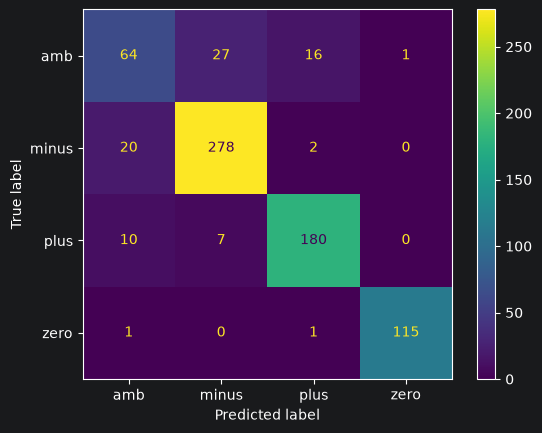

In [40]:
# Proszę wybrać finalistę na validation i wykonać jednorazowy finalny test.

final_train_df = pd.concat([train_df, val_df], ignore_index=True)
final_train_dataset = make_dataset(final_train_df, herbert_tokenizer)
test_dataset = make_dataset(test_df, herbert_tokenizer)


final_warmup_steps = int(0.1 * math.ceil(len(final_train_df) / BATCH_SIZE) * NUM_EPOCHS)


final_herbert_model = make_model(MODEL_PL)
final_herbert_trainer = make_trainer(
    model=final_herbert_model,
    learning_rate=LEARNING_RATE,
    train_ds=final_train_dataset,
    eval_ds=test_dataset,
    tok=herbert_tokenizer,
    eval_each_epoch=False,
    warmup_steps=final_warmup_steps
)

t_s = time.perf_counter()
final_herbert_trainer.train()
t_e = time.perf_counter()

final_train_s = t_e - t_s

t_s = time.perf_counter()
final_out = final_herbert_trainer.predict(test_dataset)
final_ms_doc = (time.perf_counter() - t_s) / len(test_dataset) * 1000

final_test_pred = final_out.predictions.argmax(axis=1)
test_true = final_out.label_ids
_, final_lo, final_hi = bootstrap_ci(test_true, final_test_pred, metric=macro_f1)



print(f"czas treningu: {final_train_s:.1f} s, inferencja: {final_ms_doc:.2f} ms/doc")
print(f"accuracy: {final_out.metrics['test_accuracy']:.3f}")
print(f"macro-F1: {final_out.metrics['test_macro_f1']:.3f} (95% CI: {final_lo:.3f}–{final_hi:.3f})")
print(classification_report(test_true, final_test_pred, target_names=CLASSES, digits=3))

ConfusionMatrixDisplay(confusion_matrix(test_true, final_test_pred), display_labels=CLASSES).plot()
plt.show()


In [43]:
svm_final = clone(svm_pipe).fit(final_train_df["text"], final_train_df["target"].map(label2id))
svm_test_pred = svm_final.predict(test_df["text"])
_, svm_lo, svm_hi = bootstrap_ci(test_true, svm_test_pred, metric=macro_f1)
diff, diff_lo, diff_hi = paired_bootstrap_diff(test_true, svm_test_pred, final_test_pred, metric=macro_f1)

print(f"TF-IDF + Linear SVM (test): macro-F1 {macro_f1(test_true, svm_test_pred):.3f} (95% CI: {svm_lo:.3f}–{svm_hi:.3f})")
print(f"Δ macro-F1 (HerBERT − SVM): {diff:+.3f} (95% CI: {diff_lo:+.3f} do {diff_hi:+.3f})")

TF-IDF + Linear SVM (test): macro-F1 0.791 (95% CI: 0.759–0.822)
Δ macro-F1 (HerBERT − SVM): +0.068 (95% CI: +0.030 do +0.104)


**Wynik testowy finalisty (HerBERT, trening na train + validation):** accuracy 0.882, macro-F1 0.859 (95% CI 0.830–0.883), czas treningu ok. 389 s, inferencja ok. 3.1 ms/dokument.

- **F1 per klasa:** `zero` 0.987, `plus` 0.909, `minus` 0.908, `amb` 0.631. Najtrudniejsza pozostaje klasa `amb`, ale jej F1 jest wyraźnie wyższe niż w TF-IDF + Linear SVM na tym samym teście (0.464).
- **Porównanie z baseline'em:** TF-IDF + Linear SVM na tym samym zbiorze testowym osiąga macro-F1 0.791 (finalista Lab 2, TF-IDF + LogReg: 0.800). Różnica HerBERT − SVM wynosi +0.068 (95% CI +0.030 do +0.104), więc przewaga jest istotna i potwierdza wynik walidacyjny (+0.056).
- **Koszt:** przewaga kosztuje ok. 390 s treningu zamiast ok. 1 s i ok. 3 ms zamiast ok. 0.06 ms na dokument.
- Wynik testowy jest nieco wyższy niż walidacyjny (0.859 vs 0.844), prawdopodobnie dzięki większemu zbiorowi treningowemu. Konfiguracja nie była zmieniana po obejrzeniu testu.

# Zadanie 10*: Analiza błędnych predykcji

Dla najlepszego transformera wytrenowanego wyłącznie na `train` (nie dla modelu finalnego z zadania 9) proszę wybrać dokładnie 12 błędnych predykcji ze zbioru walidacyjnego (wylosowanych z `random_state=RANDOM_STATE`).

Każdy przypadek proszę przypisać do krótkiej kategorii, np. `AMBIGUOUS_GOLD`, `MIXED_SENTIMENT`, `NEGATION`, `IRONY_SARCASM`, `LONG_CONTEXT`, `VERY_SHORT`, `LEXICAL_TRAP`, `TRUNCATION`, `NON_REVIEW`, `PRETOKENIZATION`, `OTHER`.

Tabela powinna zawierać:

| nr | tekst | gold | predykcja | typ błędu | komentarz |
|---:|---|---|---|---|---|

Proszę dodatkowo zaznaczyć, jeśli w labie stworzyli Państwo takie check, czy TF-IDF + Linear SVM (predykcje z labu 2) popełnił ten sam błąd.

Nie należy jeszcze proponować rozwiązania każdego pojedynczego błędu. Najpierw proszę wskazać powtarzające się wzorce.

In [46]:
# Proszę przygotować analizę dokładnie 12 błędnych predykcji.


herbert_lens = np.array([len(x) for x in herbert_tokenizer(val_df["text"].tolist(), truncation=False)["input_ids"]])

val_analysis = pd.DataFrame({
    "tekst": val_df["text"].values,
    "gold": [id2label[i] for i in val_true],
    "predykcja": [id2label[i] for i in herbert_ft_val_pred],
    "SVM": [id2label[i] for i in svm_val_preds],
    "n_tokens": herbert_lens,
})
val_analysis["obcięty (> MAX_LENGTH)"] = val_analysis["n_tokens"] > MAX_LENGTH
val_analysis["SVM ten sam błąd"] = val_analysis["SVM"] == val_analysis["predykcja"]

errors = val_analysis[val_analysis["gold"] != val_analysis["predykcja"]]
sample_errors = errors.sample(n=12, random_state=RANDOM_STATE)
for nr, (idx, r) in enumerate(sample_errors.iterrows(), start=1):
    print(f"[{nr}] idx={idx} | gold={r.gold} | pred={r.predykcja} | SVM={r.SVM} | tokeny={r.n_tokens}"
          f"{' (OBCIĘTY)' if r['obcięty (> MAX_LENGTH)'] else ''}")
    print(r.tekst)
    print()

[1] idx=645 | gold=minus | pred=amb | SVM=amb | tokeny=166 (OBCIĘTY)
Ładnie położony , ale z czystością jest jakiś problem . Brudna pufa i kłaki z wykładziny . Na minus brak dodatkowych kanałów TV ( kilka nie działało ) . Klimatyzacja ustawiona na zbyt niską temperaturę . W nocy było najzwyczajniej zimno . Na plus - obsługa recepcji . Pomocna , grzeczna i zainteresowana . Pani menadżer przeprosiła za niedogodności i zaprosiła na kolację , obiecując przesłanie vouchera . Okazało się jednak , że jest osobą niesłowną . Słuch o tej Pani ( która podobno odpowiada za jedzenie jako kierownik ) zaginął i jak do tej pory się nie odezwała . Zamierzam w tej sprawie napisać do marketingu za oceanem i poinformować kogo zatrudniają w swoim hotelu w Gdyni . Nie należy czegoś obiecywać , a potem nic sobie z tego nie robić .

[2] idx=469 | gold=plus | pred=amb | SVM=minus | tokeny=88
Hotel jak na 4 gwiazdki spełnia oczekiwania . Jedzenie w miarę choć szału nie było . Dobra baza wypadowa do zwiedzania .



| nr | idx | tekst | gold | predykcja | typ błędu | SVM ten sam błąd | komentarz |
|---:|---:|---|---|---|---|---|---|
| 1 | 645 | „Ładnie położony, ale z czystością jest jakiś problem… Na plus obsługa recepcji… Okazało się jednak, że [menadżerka] jest osobą niesłowną…” | minus | amb | TRUNCATION | tak | Zalety i wady na początku, a najmocniejsza krytyka (niesłowna menadżerka) jest na końcu, poza oknem 128 tokenów (tekst ma 166). |
| 2 | 469 | „Hotel jak na 4 gwiazdki spełnia oczekiwania. Jedzenie w miarę choć szału nie było… Ogólnie nie źle można polecić…” | plus | amb | MIXED_SENTIMENT | nie (SVM: minus) | Umiarkowana pochwała z kilkoma zastrzeżeniami i „nie polecam” dotyczącym biura podróży, a nie hotelu. |
| 3 | 570 | „Hotel powiedzmy robotniczy +… pościel brudna… Obsługa miła i przyjemna… W tej cenie… na pewno będzie lepszy obiekt.” | amb | minus | AMBIGUOUS_GOLD | nie (SVM poprawnie) | Przeważa krytyka, a jedyna pochwała to miła obsługa; predykcja `minus` jest uzasadniona. |
| 4 | 406 | „…przepiękne baseny… jedzenie jest smaczne i obfite… Nie podobało nam się jednak… Ale ogólnie polecam ten hotel.” | amb | plus | TRUNCATION | nie (SVM poprawnie) | Pierwsza połowa to same pochwały; zastrzeżenia (kręgle, barman, parking) i końcowy werdykt są w dużej części poza oknem (213 tokenów). |
| 5 | 402 | „…kłopot z korzystaniem z basenu, tłok, hałas… Personel niezainteresowany… Smaczne śniadania i obiadokolacje.” | amb | minus | MIXED_SENTIMENT | nie (SVM poprawnie) | Długa lista wad i jedno zdanie pochwały na końcu; model wybrał dominującą polaryzację. |
| 6 | 378 | „Jak na początek działalności to bardzo mocna 4 z plusem :) do piątki jeszcze trochę pracy… ośrodek 4,5/5, pokoje 4,5/5…” | plus | amb | LEXICAL_TRAP | nie (SVM poprawnie) | Ocena wyrażona liczbami („4,5/5”), a sformułowania „do piątki jeszcze trochę pracy” i „propozycja” wyglądają jak zastrzeżenia. |
| 7 | 237 | „Witam, nie mogę się zgodzić z negatywnymi opiniami… jest bardzo powściągliwy w słowach… Uważam że doktor jest ok.” | plus | amb | LEXICAL_TRAP | tak | Obrona lekarza pisana negatywnym słownictwem („negatywne opinie”, „oschły”, „pretensje”); werdykt „doktor jest ok” jest na końcu, poza oknem (172 tokeny). |
| 8 | 632 | „…Bardzo przyjemny pobyt… Jedynie część rekreacyjna pozostawia wiele do życzenia… Reasumując, z czystym sumieniem polecam.” | plus | amb | TRUNCATION | nie (SVM poprawnie) | Krytyka basenu jest w środku tekstu, a jednoznaczne podsumowanie „z czystym sumieniem polecam” jest na końcu, poza oknem (175 tokenów). |
| 9 | 127 | „Byłam zadowolona z przebiegu leczenia, ale niestety rozczarowałam się na sam koniec…” | amb | minus | MIXED_SENTIMENT | tak | Krótka pochwała, a potem długi opis problemu z wkładkami; ten sam przykład był błędem `amb → minus` w Lab 2. |
| 10 | 35 | „Zgadzam się z poprzednimi opiniami… z odległości 2 metrów oglądała moje stopy… teraz idę do Dra Obtułowicza, słyszałam dobre opinie…” | minus | amb | LEXICAL_TRAP | nie (SVM poprawnie) | Pozytywne słowa na końcu dotyczą innego lekarza; tekst bez polskich znaków. |
| 11 | 210 | „…Rzeczywiście miły, uprzejmy, budzący zaufanie… Uważam to za kardynalny błąd lekarza… dziecko urodziło się na skraju kwasicy…” | minus | amb | TRUNCATION | nie (SVM poprawnie) | Pochwała na początku, a najpoważniejsze zarzuty (skutki dla dziecka) są w końcówce, poza oknem (170 tokenów). |
| 12 | 305 | „Nie jestem zadowolona z leczenia… Niemniej jednak Pani doktor jest bardzo miła i profesjonalna. Jedynym minusem są…” | minus | amb | AMBIGUOUS_GOLD | tak | Tekst wprost łączy zalety i wady; etykieta `amb` byłaby równie uzasadniona jak `minus`. |

**Wynik**

| typ błędu | liczba | przykłady | obserwacja |
|---|---:|---|---|
| TRUNCATION | 4 | 1, 4, 8, 11 | Kluczowa ocena (często podsumowanie) jest na końcu tekstu, poza oknem 128 tokenów. |
| MIXED_SENTIMENT | 3 | 2, 5, 9 | Zalety i wady w jednym tekście; model wybiera dominującą polaryzację albo `amb` przy umiarkowanej pochwale. |
| LEXICAL_TRAP | 3 | 6, 7, 10 | Słownictwo o przeciwnym wydźwięku niż ocena: negatywne słowa w obronie lekarza, pozytywne o innym lekarzu, ocena liczbowa. |
| AMBIGUOUS_GOLD | 2 | 3, 12 | Etykieta jest dyskusyjna, a predykcja modelu uzasadniona. |

**Powtarzające się wzorce:**

- **Wszystkie 12 błędów dotyczy klasy `amb`:** w 4 przypadkach jest ona etykietą prawdziwą, a w 8 predykcją. Wśród wylosowanych błędów nie ma ani jednej pomyłki `plus` ↔ `minus`. Model dobrze rozróżnia skrajne oceny, a problemem jest granica „mieszana kontra jednoznaczna”, subiektywna także dla anotatorów (2 przypadki `AMBIGUOUS_GOLD`).
- **Obcięcie tekstu to realny problem:** 5 z 12 tekstów przekracza 128 tokenów, a w 4 z nich decydująca ocena jest właśnie w ucinanej końcówce. Ten typ błędu prawdopodobnie zmniejszyłoby dłuższe okno (`MAX_LENGTH`), a nie większy model.
- **SVM popełnił ten sam błąd w 4 z 12 przypadków** (1, 7, 9, 12), a w 7 przypadkach miał poprawną klasę. Wspólne błędy to teksty naprawdę niejednoznaczne lub z dyskusyjną etykietą. Błędy tylko HerBERT-a częściej wynikają z obcięcia tekstu, którego SVM nie ma, bo widzi cały tekst.

# Zadanie 11*: Interpretacja, decyzja projektowa i wnioski

To zadanie nie wymaga nowej implementacji.

Na podstawie wykonanych eksperymentów proszę odpowiedzieć:

1. Co zmieniło pełne dostrajanie względem zamrożonego enkodera?
2. Czy wzrost jakości był proporcjonalny do wzrostu kosztu treningu?
3. Jakie typy błędów dominują w analizie 12 przypadków i czy któryś z nich prawdopodobnie nie ustąpi po zwiększeniu modelu?
4. Czy wynik tego laboratorium pozwala stwierdzić, że transformer jest ogólnie lepszy od `TF-IDF + Linear SVM`? Dlaczego?
5. (jeśli wykonano Zadanie 8) Czy model polski ma przewagę nad wielojęzycznym i czy ta przewaga uzasadnia koszt?

Następnie proszę wybrać rozwiązanie dla dwóch scenariuszy: **A** (najważniejsza jest jakość), **B** (najważniejsze są niski koszt, szybkie uczenie i szybka inferencja). Dla każdego proszę podać: wybrany model, wynik jakościowy, koszt do zaakceptowania i najważniejsze ograniczenie.

Na końcu jednym akapitem: **Kiedy dodatkowa złożoność transformera jest uzasadniona, a kiedy mocny model klasyczny pozostaje lepszą decyzją inżynierską?**ę

Proszę przygotować wnioski dotyczące zadania (5-8 krótkich wniosków opartych na wynikach, obejmujących tokenizację, MAX_LENGTH, frozen vs fine-tuning, SVM vs transformer, koszt i błędy).

**1. Co zmieniło pełne dostrajanie względem zamrożonego enkodera?**

Macro-F1 na walidacji wzrosło z 0.581 do 0.768 (accuracy z 0.678 do 0.786). Przy zamrożonym enkoderze uczy się tylko głowa (593 668 parametrów, 0.44%), a reprezentacje z pretreningu MLM nie oddzielają sentymentu. Pełne dostrajanie dopasowuje wszystkie 135 mln parametrów do zadania.

**2. Czy wzrost jakości był proporcjonalny do wzrostu kosztu treningu?**

Nie. Pełne dostrajanie było ok. 10× droższe od wariantu zamrożonego (303 s vs 31 s) i dało +0.19 macro-F1, ale względem TF-IDF + Linear SVM (ok. 1 s) ten sam DistilBERT był ok. 300× droższy, a nie lepszy (0.768 vs 0.788, Δ w granicach CI). Dopiero HerBERT (351 s) dał istotny zysk: +0.056 macro-F1 na walidacji i +0.068 na teście.

**3. Jakie typy błędów dominują i czy któryś nie ustąpi po zwiększeniu modelu?**

Wszystkie 12 błędów dotyczy granicy z klasą `amb`: TRUNCATION (4), MIXED_SENTIMENT (3), LEXICAL_TRAP (3), AMBIGUOUS_GOLD (2). Większy model nie usunie błędów `AMBIGUOUS_GOLD`, bo dotyczą dyskusyjnych etykiet, ani `TRUNCATION`, bo ocena leży poza oknem 128 tokenów. Ten drugi typ wymaga dłuższego `MAX_LENGTH`, a nie większego modelu.

**4. Czy wynik pozwala stwierdzić, że transformer jest ogólnie lepszy od TF-IDF + Linear SVM?**

Nie. Wynik zależy od konkretnego modelu: wielojęzyczny DistilBERT był statystycznie nieodróżnialny od SVM (Δ −0.020, CI −0.056…+0.013), a polski HerBERT istotnie lepszy (Δ +0.068 na teście, CI +0.030…+0.104). To jeden zbiór, dwie domeny, `MAX_LENGTH=128`, 3 epoki bez strojenia i jeden seed, więc wniosek dotyczy tej konfiguracji, a nie „transformerów w ogóle”.

**5. Czy model polski ma przewagę nad wielojęzycznym i czy uzasadnia ona koszt?**

Tak. HerBERT jest istotnie lepszy od DistilBERT-a (Δ +0.076, CI +0.045…+0.107) przy podobnym koszcie treningu (351 vs 303 s, ok. 1.2×) i ok. 2× wolniejszej inferencji (2.8 vs 1.4 ms/dok.). Ma przy tym mniej parametrów (124 vs 135 mln) i krótsze sekwencje (59% obciętych tekstów vs 84%). Względem DistilBERT-a przewaga uzasadnia koszt.

**Scenariusz A: najważniejsza jest jakość → fine-tuned HerBERT.** Wynik: macro-F1 0.859 na teście (CI 0.830–0.883), F1 dla `amb` 0.631. Koszt: ok. 6.5 min treningu na GPU (MPS), ok. 3 ms/dokument, model ok. 0.5 GB. Ograniczenie: obcina 59% recenzji do 128 tokenów, a `amb` wciąż jest słaba.

**Scenariusz B: niski koszt, szybkie uczenie i inferencja → TF-IDF + Linear SVM.** Wynik: macro-F1 0.791 na teście (CI 0.759–0.822). Koszt: ok. 1 s treningu na CPU, ok. 0.06 ms/dokument, model kilka MB. Ograniczenie: nie rozumie kontekstu ani negacji, F1 dla `amb` tylko 0.464.

**Kiedy złożoność transformera jest uzasadniona?** Gdy zysk jakości jest istotny statystycznie i ważny dla zastosowania, a dostępny jest model pretrenowany na danym języku. U nas dopiero polski HerBERT przebił baseline o ok. 0.07 macro-F1, głównie dzięki lepszemu rozpoznawaniu opinii mieszanych. Mocny model klasyczny pozostaje lepszą decyzją, gdy liczy się koszt, szybkość i prostota wdrożenia, gdy dostępny transformer nie jest dopasowany do języka (wielojęzyczny DistilBERT nie był lepszy od SVM przy ok. 300× wyższym koszcie treningu) albo gdy teksty są długie, a okno modelu je obcina.

**Wnioski**

1. **Tokenizacja:** tokenizer HerBERT-a jest lepiej dopasowany do polskiego: 1.46 tokenu na słowo zamiast 2.17 u DistilBERT-a, całe słowa zamiast fragmentów („dobry”, „łóżku”). Oba zamieniają emoji na token nieznany.
2. **`MAX_LENGTH=128`:** przy tej wartości DistilBERT obcina 84% tekstów treningowych (mediana 222 tokeny, p95 524), a HerBERT 59%. 128 przyjęliśmy jako kompromis kosztowy; w 4 z 12 analizowanych błędów decydująca ocena była w obciętej końcówce.
3. **Frozen vs fine-tuning:** sama głowa na zamrożonym enkoderze daje tylko 0.581 macro-F1; pełne dostrajanie podnosi wynik do 0.768 przy ok. 10× dłuższym treningu.
4. **SVM vs transformer:** wielojęzyczny DistilBERT nie jest lepszy od TF-IDF + Linear SVM (0.768 vs 0.788, różnica nieistotna), a polski HerBERT jest istotnie lepszy na walidacji (0.844) i na teście (0.859 vs 0.791).
5. **Koszt:** przewaga HerBERT-a kosztuje ok. 390 s treningu zamiast 1 s i ok. 3 ms zamiast 0.06 ms na dokument; liczba parametrów nie przewiduje kosztu (HerBERT ma mniej parametrów niż DistilBERT, ale 2× więcej warstw i jest ok. 2× wolniejszy).
6. **Błędy:** wszystkie analizowane błędy dotyczą klasy `amb`, a brak pomyłek `plus` ↔ `minus`; część wynika z obcięcia tekstu lub dyskusyjnej etykiety, więc nie zniknie po samym zwiększeniu modelu.

# Karta modelu

Proszę utworzyć:

```text
artifacts/transformer_model_card.md
```

Karta powinna zawierać:

## Model
- checkpoint;
- typ architektury;
- (opcjonalnie) checkpoint modelu polskiego i liczba parametrów;
- liczba parametrów.

## Tokenizator
- checkpoint;
- `MAX_LENGTH`;
- procent tekstów obciętych przy `MAX_LENGTH`;
- (jeśli wykonano Zadanie 8) porównanie z tokenizatorem HerBERT-a (tokeny na słowo);
- sposób paddingu i obcinania.

## Zadanie
- przewidywane klasy;
- mapowanie `label2id` i `id2label`.

## Dane
- liczebność `train`, `validation`, `test`;
- ewentualne ograniczenie liczby przykładów z powodów sprzętowych.

## Trening
- batch size;
- learning rate;
- liczba epok;
- wariant: frozen / fine-tuned;
- liczba parametrów trenowalnych.

## Wyniki
- `TF-IDF + Linear SVM`;
- frozen transformer;
- fine-tuned transformer;
- fine-tuned HerBERT (jeśli wykonano);
- finalny wynik testowy.

## Koszt
- urządzenie;
- czas treningu;
- ms/dokument.

## Błędy
- dominujące typy błędów z analizy 12 przypadków.

## Zastosowanie
- kiedy użycie transformera jest uzasadnione;
- kiedy prostszy baseline może być lepszym wyborem.

## Ograniczenia
- ograniczenia danych;
- ograniczenia eksperymentu;
- czego wyniki tego laboratorium nie pozwalają stwierdzić.

Karta została zapisana w pliku [`artifacts/transformer_model_card.md`](../artifacts/transformer_model_card.md). Model finalny to **fine-tuned HerBERT** (`allegro/herbert-base-cased`): macro-F1 0.859 na teście wobec 0.791 dla TF-IDF + Linear SVM (Δ +0.068, 95% CI +0.030…+0.104). Decyzja dotycząca `MAX_LENGTH=128` i procent obciętych tekstów (84.3% dla tokenizera DistilBERT-a, 59.2% dla HerBERT-a) są zapisane w sekcji „Tokenizator”.

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] audyt tokenizacji dla co najmniej 8 przykładów;
- [ ] analizę `input_ids`, `attention_mask` i porównanie sposobów paddingu;
- [ ] analizę długości tokenowych i decyzję dotyczącą `MAX_LENGTH`;
- [ ] odczyt parametrów architektury, liczbę parametrów i koszt pamięci wag;
- [ ] ręczne przejście w przód bez `pipeline()` oraz mean pooling;
- [ ] analizę logitów i wyniku softmax;
- [ ] samodzielnie przygotowany pipeline treningowy;
- [ ] trening przy zamrożonym enkoderze (z osobno dobranym learning rate);
- [ ] pełne dostrajanie;
- [ ] tabelę porównawczą na validation z przedziałami ufności;
- [ ] porównanie z HerBERT-em, w tym paired bootstrap *(opcjonalnie)*;
- [ ] wybór konfiguracji na validation i jednorazową ocenę na test (z porównaniem do baseline'u z Lab 2);
- [ ] tabelę dokładnie 12 błędnych predykcji (model trenowany tylko na `train`);
- [ ] odpowiedzi do zadania interpretacyjnego (Zadanie 11);
- [ ] plik `artifacts/transformer_model_card.md`.